# Modeling experiments
Run from the project root. This notebook shares its modeling implementation with notebook.ipynb through modeling_workflow.py.

Keep `modeling_workflow.py` alongside this notebook when running or sharing it. Run all cells from the project root; CSV result files are regenerated by the notebook.


## Modeling: predicting total_UPDRS

We predict total UPDRS only. Both UPDRS columns and patient ID are excluded from predictors. The task is generalization to unseen patients, using the original 80/20 patient split (seed 42).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from modeling_workflow import load_split, compare_models, final_evaluation

X_train, X_test, y_train, y_test, groups_train, groups_test = load_split()
print(f"Training: {len(X_train)} recordings, {groups_train.nunique()} patients")
print(f"Test: {len(X_test)} recordings, {groups_test.nunique()} patients")
assert set(groups_train).isdisjoint(groups_test)
assert not {"subject#", "motor_UPDRS", "total_UPDRS"}.intersection(X_train.columns)

Training: 4640 recordings, 33 patients
Test: 1235 recordings, 9 patients


### Features and validation

Compare demographics (age, sex, recording time), voice alone, voice plus demographics, and log voice plus demographics. Log transforms use the natural logarithm of positive jitter, shimmer, and NHR values; unlike log1p, this meaningfully transforms very small values. A regularized quadratic model tests squared terms and interactions. Fixed feature sets replace supervised forward selection performed outside validation.

All scaling and transformations happen inside each pipeline. Five shared outer GroupKFold splits estimate performance; three inner patient-grouped folds select hyperparameters by MAE within each outer training subset. Untuned models use the same outer folds. This prevents both preprocessing leakage and reporting the same folds used to tune hyperparameters. Parameter grids are deliberately small for a reproducible run; they do not exhaust all possible improvements. See modeling_workflow.py for the exact candidates.

MAE is primary, with RMSE and R² as supporting metrics. Fold R² can be negative when a model is worse than that validation fold's own mean. The explicit mean baseline uses only the training fold's mean. The best result across many candidates may still be optimistic; reserve the held-out patients for one final evaluation.

In [2]:
comparison, specs = compare_models(X_train, y_train, groups_train)

Mean baseline: nested CV MAE 8.971
Linear / Demographics: nested CV MAE 8.832
Ridge / Demographics: nested CV MAE 8.712
Lasso / Demographics: nested CV MAE 8.632
KNN / Demographics: nested CV MAE 9.788
Tree / Demographics: nested CV MAE 10.561
SVR / Demographics: nested CV MAE 12.034
Forest / Demographics: nested CV MAE 11.052
Linear / Voice only: nested CV MAE 9.834
Ridge / Voice only: nested CV MAE 9.537
Lasso / Voice only: nested CV MAE 9.208
KNN / Voice only: nested CV MAE 9.467
Tree / Voice only: nested CV MAE 9.466
SVR / Voice only: nested CV MAE 10.169
Forest / Voice only: nested CV MAE 9.464
Linear / Voice + demographics: nested CV MAE 9.651
Ridge / Voice + demographics: nested CV MAE 9.099
Lasso / Voice + demographics: nested CV MAE 8.644
KNN / Voice + demographics: nested CV MAE 9.555
Tree / Voice + demographics: nested CV MAE 10.163
SVR / Voice + demographics: nested CV MAE 10.978
Forest / Voice + demographics: nested CV MAE 11.156
Linear / Log voice + demographics: nested C

/Users/evanwhite/School/CS363M/parkinsons/.venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/evanwhite/School/CS363M/parkinsons/.venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/Users/evanwhite/School/CS363M/parkinsons/.venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


## Comparison

Metrics below are outer-fold means. MAE SD describes variation between folds, not a confidence interval. Positive tuning gain and MAE improvement indicate improvement over the untuned model and mean baseline, respectively.

,candidate,train MAE,untuned CV MAE,CV MAE,CV MAE SD,CV RMSE,CV R2,MAE improvement %,MAE tuning gain
0,Lasso / Demographics,8.244,8.632,8.632,1.816,10.315,-0.096,3.769,0.000
1,Lasso / Voice + demographics,8.134,8.644,8.644,1.831,10.365,-0.099,3.641,0.000
2,Lasso / Log voice + demographics,8.129,8.651,8.651,1.837,10.372,-0.100,3.561,0.000
3,Ridge / Demographics,8.272,8.832,8.712,1.733,10.382,-0.124,2.878,0.120
4,Linear / Demographics,8.303,8.832,8.832,1.723,10.448,-0.152,1.543,0.000
5,Mean baseline,8.879,8.971,8.971,2.158,10.977,-0.234,0.000,0.000
6,Ridge / Voice + demographics,8.003,9.641,9.099,1.706,10.726,-0.178,-1.430,0.542
7,Ridge / Log voice + demographics,7.946,9.869,9.159,1.713,10.849,-0.207,-2.096,0.711
8,Lasso / Voice only,8.724,9.208,9.208,2.103,11.172,-0.274,-2.650,0.000
9,KNN / Log voice + demographics,7.939,11.911,9.439,2.148,11.304,-0.297,-5.218,2.473


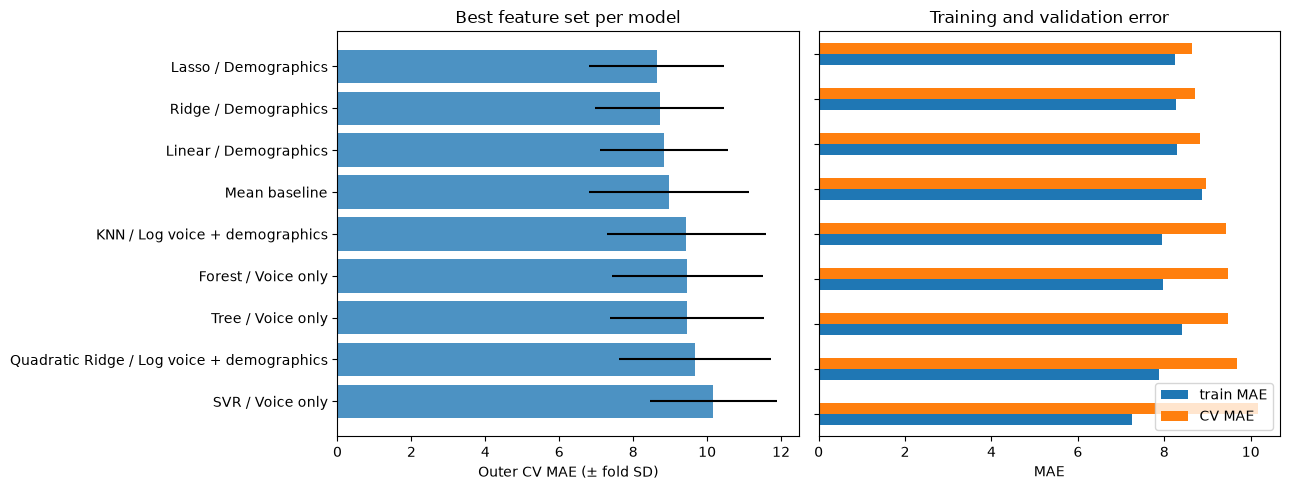

In [3]:
display(comparison.round(3))
comparison.to_csv("model_comparison.csv", index=False)

best_by_model = comparison.assign(family=comparison.candidate.str.split(" / ").str[0]).drop_duplicates("family")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot = best_by_model.sort_values("CV MAE", ascending=False)
axes[0].barh(plot.candidate, plot["CV MAE"], xerr=plot["CV MAE SD"], alpha=.8)
axes[0].set(xlabel="Outer CV MAE (± fold SD)", title="Best feature set per model")
plot.set_index("candidate")[["train MAE", "CV MAE"]].plot.barh(ax=axes[1])
axes[1].set(xlabel="MAE", ylabel="", title="Training and validation error")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

## Final held-out evaluation

Select the smallest outer CV MAE, retune only on all training patients, and evaluate the selected model and training-mean baseline on the held-out patients. Do not use these test results to select further models. A large train/validation gap indicates possible overfitting; weak validation across models may indicate limited predictive information for new patients.

In [4]:
final_search, test_report, test_errors = final_evaluation(
    comparison, specs, X_train, X_test, y_train, y_test, groups_train, groups_test)
print("Selected by CV MAE:", comparison.iloc[0]["candidate"])
print("Final training-only tuning:", final_search.best_params_)
display(test_report.round(3))
test_report.to_csv("final_test_metrics.csv", index=False)
test_errors.to_csv("final_test_predictions.csv", index=False)

Selected by CV MAE: Lasso / Demographics
Final training-only tuning: {'model__alpha': 1}


,model,test MAE,test RMSE,test R2
0,Lasso / Demographics,9.544,10.425,-0.312
1,Mean baseline,7.991,9.467,-0.082


### Prediction and residual diagnostics

Residual = actual − predicted. Positive residuals mean underprediction. Patient MAE gives each patient a separate summary. Severity bins are descriptive only; they are not clinical categories.

Equal-patient average MAE: 9.628


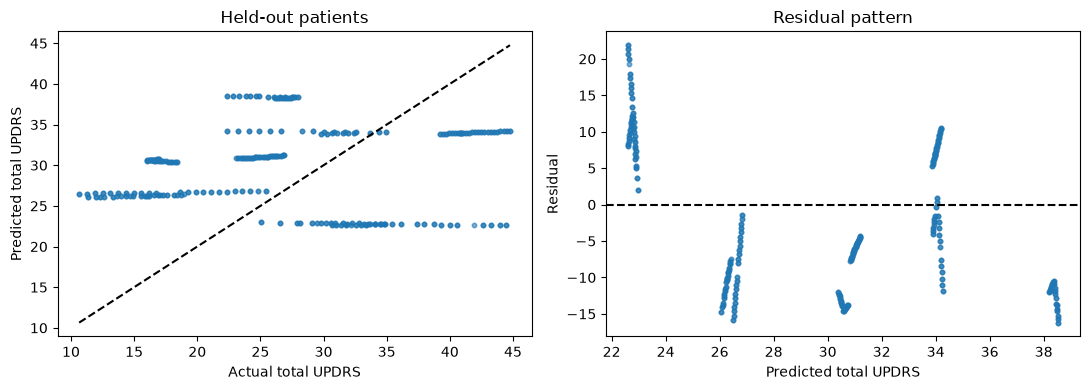

,recordings,mean_score,MAE,bias
patient,,,,
5,156,41.854,7.825,7.825
9,152,25.077,5.945,-5.945
14,136,18.017,8.650,-8.650
20,134,16.931,13.642,-13.642
26,130,31.332,8.564,8.564
27,129,15.434,10.812,-10.812
30,126,36.903,14.149,14.149
31,130,29.559,4.638,-4.519
40,142,25.954,12.429,-12.429


,recordings,patients,MAE,bias
actual score range,,,,
<20,346,3,12.124,-12.124
20–30,441,6,7.967,-7.029
30–40,277,4,8.024,6.857
>=40,171,2,10.857,10.857


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(test_errors.actual, test_errors.predicted, s=10, alpha=.25)
limits = [min(test_errors.actual.min(), test_errors.predicted.min()),
          max(test_errors.actual.max(), test_errors.predicted.max())]
axes[0].plot(limits, limits, "k--")
axes[0].set(xlabel="Actual total UPDRS", ylabel="Predicted total UPDRS", title="Held-out patients")
axes[1].scatter(test_errors.predicted, test_errors.residual, s=10, alpha=.25)
axes[1].axhline(0, color="k", linestyle="--")
axes[1].set(xlabel="Predicted total UPDRS", ylabel="Residual", title="Residual pattern")
plt.tight_layout()
plt.show()

patient_errors = test_errors.groupby("patient").agg(
    recordings=("actual", "size"), mean_score=("actual", "mean"),
    MAE=("absolute error", "mean"), bias=("residual", "mean"))
display(patient_errors.round(3))
print(f"Equal-patient average MAE: {patient_errors.MAE.mean():.3f}")
severity = pd.cut(test_errors.actual, bins=[-np.inf, 20, 30, 40, np.inf],
                  labels=["<20", "20–30", "30–40", ">=40"], right=False)
display(test_errors.groupby(severity.rename("actual score range"), observed=True).agg(
    recordings=("actual", "size"), patients=("patient", "nunique"),
    MAE=("absolute error", "mean"), bias=("residual", "mean")).round(3))

### Interpretation and limits

Use the tables to identify whether voice adds value beyond demographics and whether tuning or log transforms help. The comparison ranks by MAE; it does not optimize R² or guarantee positive R². Report an unsuccessful experiment honestly rather than weakening the patient separation.

There are only 42 patients despite thousands of recordings. Related recordings and interpolated targets limit independent information. The held-out result describes these patients and this split; it does not establish clinical utility. Fold variation and per-patient errors show sensitivity to the patients sampled. Team members must interpret the observed results and write the required process PDF themselves.

### Findings from the saved run

Demographics-only Lasso was selected by nested CV MAE (8.632 versus 8.971 for the mean baseline, a 3.77% improvement). Its mean fold R² remained negative (−0.096). Adding raw voice measurements gave MAE 8.644, log voice measurements 8.651, and the quadratic model 9.673; none improved on demographics alone. The best voice-only model had MAE 9.208, worse than the mean baseline. These experiments provide no evidence that voice features improve prediction for unseen patients under this protocol.

On the nine held-out patients, the selected model had MAE 9.544, RMSE 10.425, and R² −0.312. The mean baseline performed better (MAE 7.991, RMSE 9.467, R² −0.082). The small validation gain did not generalize to this test split. We retain the model selected by CV and report this failure; we do not use the test set to choose a replacement. Improving R² remains unresolved, and this result does not support deployment for new patients.
